In [2]:
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.patches as patches
import matplotlib.transforms as transforms
from astropy.coordinates import SkyCoord
import astropy.units as u


In [7]:

square_side= 6 #deg
sampling=8  #pointings per side
factor=square_side/sampling
ra='23h42m42.5s'
dec='-14d32m52.5s'
center=SkyCoord(ra, dec, frame='icrs')
ref_coord = np.array([center.ra.deg,center.dec.deg, 0 ])  #ra dec rot


In [8]:
plt.close('all')

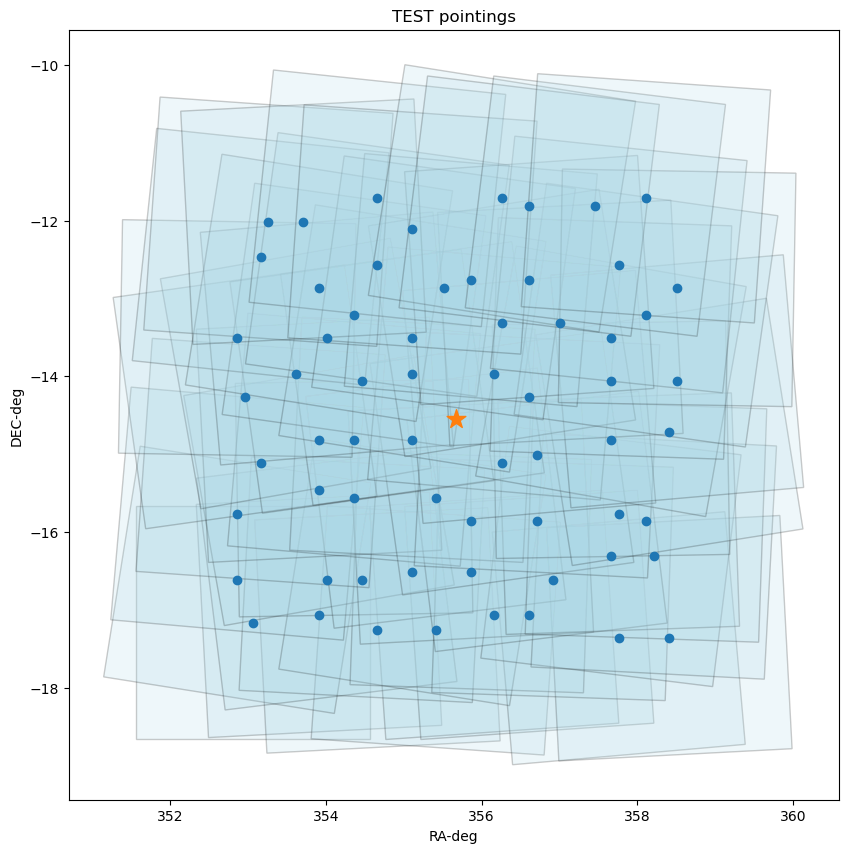

<SkyCoord (ICRS): (ra, dec) in deg
    (355.67708333, -14.54791667)>


In [9]:
mat=np.zeros((sampling**2,3))
mat[:]=ref_coord
mat[:,0]+=np.arange(sampling**2)%sampling*factor
mat[:,1]+= np.arange(sampling**2)//sampling*factor
#here mat has a regular grid of samploing**2 points
for i in range(1,len(mat)):
    rnd_off_ra = np.random.randint(1,3)/10 *np.random.choice([1, -1])
    rnd_off_de = np.random.randint(1,3)/10  *np.random.choice([1, -1])
    rnd_off_r  = np.random.randint(1,11)   *np.random.choice([1, -1])
    #we add some random variations to the regular grid
    mat[i]+=[rnd_off_ra,rnd_off_de,rnd_off_r]
adj=[np.abs(center.ra.deg-np.mean(mat[:,0])), np.abs(center.dec.deg-np.mean(mat[:,1])),0]
mat-=adj
fig, ax = plt.subplots()
fig.set_size_inches(18, 10)
for i in range(len(mat)):
    width= 3.0
    ra=mat[:,0]-width/2
    de=mat[:,1]-width/2
    # Create the rectangle
    rect = patches.Rectangle(
        (ra[i], de[i]), width, width,
        linewidth=1, edgecolor='black', facecolor='lightblue',alpha=0.2
    )
    
    t = transforms.Affine2D().rotate_deg_around(mat[i,0], mat[i,1], mat[i,2])
    rect.set_transform(t + ax.transData)
    # Add rectangle to the axes
    ax.add_patch(rect)

plt.scatter(mat[:,0],mat[:,1])

ax.set_aspect('equal')
ax.set_xlabel('RA-deg')
ax.set_ylabel('DEC-deg')
plt.title('TEST pointings')
plt.scatter(center.ra.deg,center.dec.deg,marker='*', s=200)
plt.show()

print(center)


In [10]:
#ABSOLUTE OFFSETS FROM THE CENTER OF THE FIELD


In [11]:
offset_abs=np.zeros(mat.shape)
offset_abs[:,0]=mat[:,0]-center.ra.deg
offset_abs[:,1]=mat[:,1]-center.dec.deg
offset_abs[:,2]=mat[:,2]
print(mat)
np.save('../data/pointings/TEST_pointings_offsets.npy', mat)

[[353.06145833 -17.16510417   0.        ]
 [353.91145833 -17.06510417   3.        ]
 [354.66145833 -17.26510417   3.        ]
 [355.41145833 -17.26510417  -4.        ]
 [356.16145833 -17.06510417   4.        ]
 [356.61145833 -17.06510417   4.        ]
 [357.76145833 -17.36510417   5.        ]
 [358.41145833 -17.36510417   3.        ]
 [352.86145833 -16.61510417  -9.        ]
 [354.01145833 -16.61510417   7.        ]
 [354.46145833 -16.61510417  -3.        ]
 [355.11145833 -16.51510417  -9.        ]
 [355.86145833 -16.51510417  -2.        ]
 [356.91145833 -16.61510417  -2.        ]
 [357.66145833 -16.31510417  -7.        ]
 [358.21145833 -16.31510417  -3.        ]
 [352.86145833 -15.76510417  -5.        ]
 [353.91145833 -15.46510417  10.        ]
 [354.36145833 -15.56510417   1.        ]
 [355.41145833 -15.56510417   7.        ]
 [355.86145833 -15.86510417   3.        ]
 [356.71145833 -15.86510417   7.        ]
 [357.76145833 -15.76510417   2.        ]
 [358.11145833 -15.86510417  -2.  

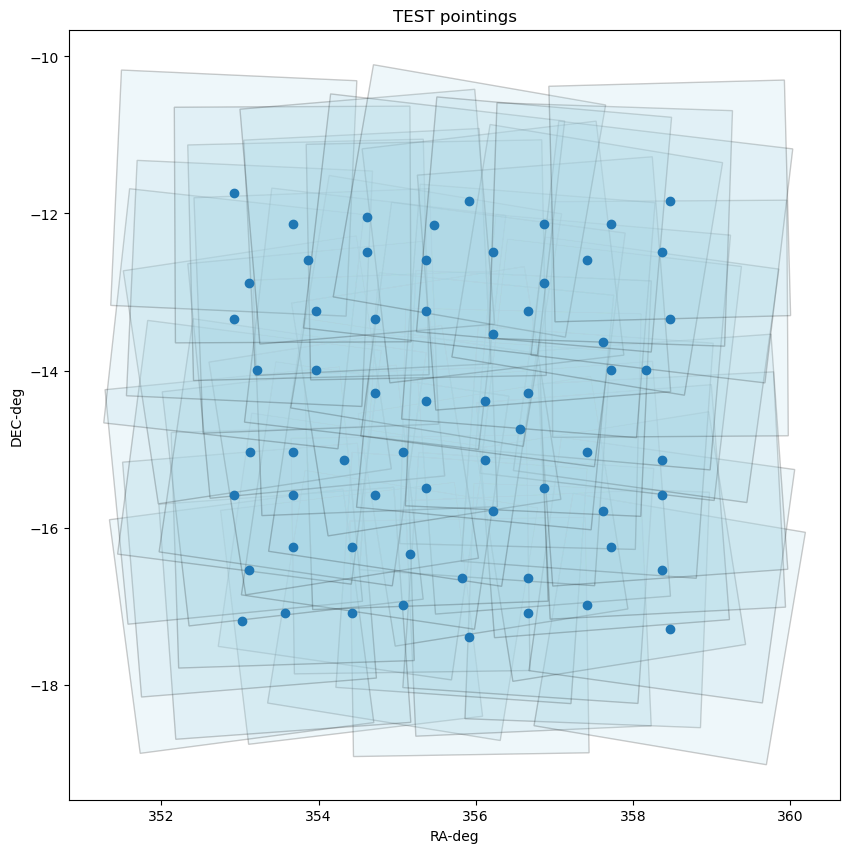

In [11]:
import lsst.daf.butler as dafButler
import numpy as np
from lsst.summit.utils import ConsDbClient
import matplotlib.pyplot as plt




URL = "http://consdb-pq.consdb:8080/consdb"  
os.environ["no_proxy"] += ",.consdb"
cdb_client = ConsDbClient(URL)
visit=None
query_table = f"""
        SELECT
            visit_id AS id,
            physical_rotator_angle AS rot_ang
        FROM
            cdb_lsstcam.visit1_quicklook
""" 

butler = dafButler.Butler("embargo", collections=["LSSTCam/runs/nightlyValidation","LSSTCam/raw/all"], instrument="LSSTCam")

visit_list=list(range(2025121200069,2025121200093)) + list( range(2025121900041,2025121900081))
# visit_list.append(

dec= np.zeros(len(visit_list))
ra= np.zeros(len(visit_list))
fig, ax = plt.subplots()
fig.set_size_inches(18, 10)

for i,visit in enumerate(visit_list):
        
        result_df = cdb_client.query(query_table).to_pandas()
        
        rot=result_df['rot_ang'][result_df['id']==visit].iloc[0]
        # print(rot.values)

        ra[i]=butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
        dec[i] = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()


        width= 3.0
        rasq=ra-width/2
        desq=dec-width/2
        # Create the rectangle
        rect = patches.Rectangle(
            (rasq[i], desq[i]), width, width,
            linewidth=1, edgecolor='black', facecolor='lightblue',alpha=0.2
        )
        
        t = transforms.Affine2D().rotate_deg_around(ra[i], dec[i], rot)
        # print(rot)
        rect.set_transform(t + ax.transData)
        # Add rectangle to the axes
        ax.add_patch(rect)
        
plt.scatter(ra,dec)

ax.set_aspect('equal')
ax.set_xlabel('RA-deg')
ax.set_ylabel('DEC-deg')
plt.title('TEST pointings')
# plt.scatter(center.ra.deg,center.dec.deg,marker='*', s=200)
plt.show()

        